# 🏜️ boonta QuickStart

This notebook trains PPO to play Breakout with boonta, in plain Python and without Hydra. It builds each part of a run by hand, the same parts a [recipe](hangar/recipes/README.md) builds from a config:

1. an **environment**, wrapped to reset itself and record episode statistics
2. a **network**, a policy and a value head
3. an **algorithm**, PPO
4. a **podracer**, Anakin, which compiles acting, stepping and learning into one program

At the end it watches the trained agent play.

Run it from a checkout:

```bash
uv sync
uv run --with jupyter jupyter lab quickstart.ipynb
```

Training takes about a minute on a GPU and about ten on a CPU. Anakin splits the environments across every device it finds.

In [1]:
import io

import flax.linen as nn
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from IPython.display import Image
from PIL import Image as PILImage

from boonta import environments
from boonta.algorithms.ppo import PPO, PPOConfig
from boonta.environments.wrappers import RecordEpisodeStatistics, SameStepAutoReset
from boonta.networks import ActorCritic, Categorical, FeatureExtractor, Network
from boonta.networks.layers import Flatten
from boonta.podracers import anakin
from boonta.utils import mesh

jax.devices()

[CpuDevice(id=0)]

## The environment

`environments.make` looks up a game by its namespace and id. Breakout here is the [MinAtar](https://github.com/kenjyoung/MinAtar) version from [Gymnax](https://github.com/RobertTLange/gymnax), written in JAX. Its screen is a 10 × 10 grid with one channel for each kind of object: the paddle, the ball, the ball's trail and the bricks. The agent has three actions: stay, left and right.

In [2]:
game = environments.make(namespace="gymnax", env_id="Breakout-MinAtar")
num_actions = game.action_space().num_actions
game.observation_space().shape, num_actions

((10, 10, 4), 3)

`draw` paints each channel in its own colour, with a line between cells, so the observations can be looked at.

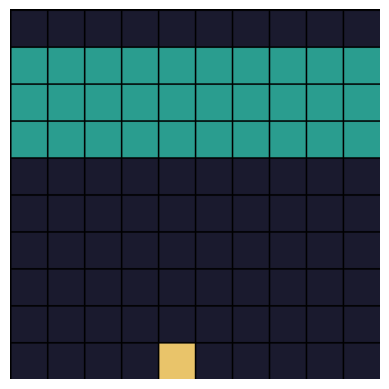

In [3]:
colours = np.array(
    [
        [26, 26, 46],  # background
        [233, 196, 106],  # paddle
        [231, 111, 81],  # ball
        [244, 162, 97],  # trail
        [42, 157, 143],  # brick
    ],
    dtype=np.uint8,
)


def draw(obs, scale=24):
    obs = np.asarray(obs).astype(bool)
    layer = np.zeros(obs.shape[:2], dtype=int)
    for channel in range(obs.shape[-1]):
        layer = np.where(obs[..., channel], channel + 1, layer)
    image = colours[layer].repeat(scale, axis=0).repeat(scale, axis=1)
    image[::scale] = image[:, ::scale] = 0
    return image


_, timestep = game.init(jax.random.key(0))
plt.imshow(draw(timestep.obs))
plt.axis("off");

The game plays one episode. `SameStepAutoReset` vectorizes it over `num_envs` copies and starts a new episode in the same step one ends. `RecordEpisodeStatistics` goes on the outside and logs the return and length of every finished episode.

`init` returns the environment state and a `Timestep`, which holds `obs`, the last `action`, `reward`, `terminated`, `truncated` and `info`, each with a leading axis of `num_envs`.

In [4]:
num_envs = 8192
num_steps = 16
gamma = 0.989

env = SameStepAutoReset(game, num_envs=num_envs)
env = RecordEpisodeStatistics(env, gamma=gamma)

_, timestep = env.init(jax.random.key(0))
timestep.obs.shape

(8192, 10, 10, 4)

## The network

A `Network` is a feature extractor followed by a head. The extractor here is a small convolution over the grid. The head is `ActorCritic`: a `Categorical` policy over the actions next to a scalar value. See the [networks guide](boonta/networks/README.md) for recurrent torsos, stacks and pretrained models.

In [5]:
network = Network(
    feature_extractor=FeatureExtractor(
        observation_extractor=nn.Sequential(
            [
                lambda obs: obs.astype(jnp.float32),
                nn.Conv(16, (3, 3), padding="VALID"),
                nn.relu,
                Flatten(start_dim=-3),
                nn.Dense(128),
                nn.relu,
            ]
        ),
    ),
    head=ActorCritic(
        actor=Categorical(nn.Dense(num_actions)),
        critic=nn.Dense(1),
    ),
)

## The algorithm

An algorithm takes its hyperparameters as a config dataclass, a network and an optax optimizer. It never sees the environment or the devices. These hyperparameters were tuned for MinAtar Breakout with [CARBS](https://github.com/imbue-ai/carbs). The defaults in `hangar` are made for every MinAtar game at once, and they take about twice the steps to leave the early plateau, where the agent breaks a few bricks and then misses the ball.

In [6]:
algorithm = PPO(
    cfg=PPOConfig(
        num_minibatches=16,
        update_epochs=4,
        clip_coefficient=0.14,
        clip_value_loss=True,
        entropy_coefficient=0.003,
        value_coefficient=0.5,
        gamma=gamma,
        gae_lambda=0.77,
        normalize_advantage=True,
    ),
    network=network,
    optimizer=optax.chain(
        optax.clip_by_global_norm(1.5),
        optax.adam(2.4e-3),
    ),
)

## The podracer

The podracer is the training loop. `anakin.make` jit-compiles `init`, `train` and `evaluate`, and builds their shardings over the mesh. `mesh(jax.device_count())` spans every device, and the environments are split along it.

Each update plays `num_steps` steps in every environment and then trains on them, so one update consumes `batch_size = num_envs × num_steps` steps.

In [7]:
podracer = anakin.make(
    config=anakin.AnakinConfig(
        num_envs=num_envs,
        num_steps=num_steps,
        mesh=mesh(jax.device_count()),
    ),
    algorithm=algorithm,
    environment=env,
)
podracer.batch_size

131072

## Train

`train(state, key, num_updates)` runs exactly `num_updates` updates in one compiled call and returns the new state and its logs. The first call compiles, the rest reuse the program.

The logs hold one entry per environment step. Episode statistics are `NaN` in the steps where no episode ended, so they are averaged with `np.nanmean`. About ten million steps take the return from below 1 to about 30.

In [8]:
num_epochs = 15
num_updates = 5

key = jax.random.key(0)
init_key, train_key, evaluate_key, play_key = jax.random.split(key, 4)

state = podracer.init(init_key)

returns = []
for epoch, epoch_key in enumerate(jax.random.split(train_key, num_epochs)):
    state, logs = podracer.train(state, epoch_key, num_updates)
    returns.append(np.nanmean(jax.device_get(logs["episode_statistics/episode_return"])))
    print(f"epoch {epoch:2d}  steps {int(state.algorithm_state.step):>10,}  return {returns[-1]:5.1f}")

epoch  0  steps    655,360  return   0.6


epoch  1  steps  1,310,720  return   2.6


epoch  2  steps  1,966,080  return   5.1


epoch  3  steps  2,621,440  return   8.0


epoch  4  steps  3,276,800  return   8.8


...

epoch 10  steps  7,208,960  return  26.0


epoch 11  steps  7,864,320  return  25.2


epoch 12  steps  8,519,680  return  23.2


epoch 13  steps  9,175,040  return  27.9


epoch 14  steps  9,830,400  return  30.2


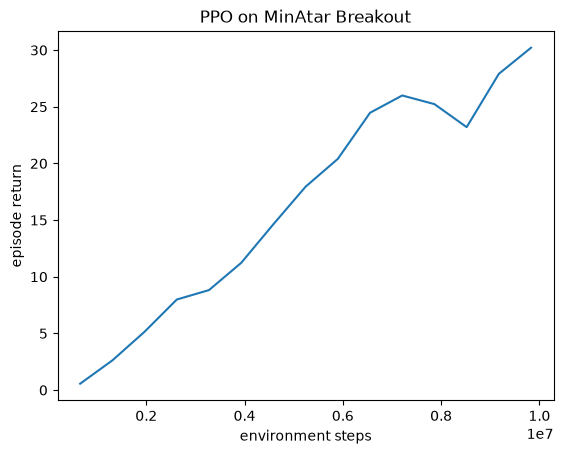

In [9]:
steps = podracer.batch_size * num_updates * np.arange(1, num_epochs + 1)
plt.plot(steps, returns)
plt.xlabel("environment steps")
plt.ylabel("episode return")
plt.title("PPO on MinAtar Breakout");

## Evaluate

`evaluate(state, key, num_steps)` restarts the environments and plays `num_steps` greedy steps. It leaves the training state alone.

In [10]:
_, logs = podracer.evaluate(state, evaluate_key, 1_000)
np.nanmean(jax.device_get(logs["episode_statistics/episode_return"]))

np.float32(40.78519)

## Watch it play

The podracer plays thousands of games at once. To watch one, step a single environment by hand. `algorithm.step(algorithm_state, key, timestep, temperature)` returns the action for a timestep, and temperature `0.0` picks the greedy one. `jax.lax.scan` plays the frames in one compiled loop.

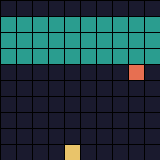

In [11]:
viewer = SameStepAutoReset(game, num_envs=1)


@jax.jit
def play(key, algorithm_state):
    reset_key, *step_keys = jax.random.split(key, 301)

    def frame(carry, key):
        env_state, timestep = carry
        action_key, env_key = jax.random.split(key)
        _, action, _ = algorithm.step(algorithm_state, action_key, timestep, 0.0)
        env_state, timestep = viewer.step(env_key, env_state, action)
        return (env_state, timestep), timestep.obs[0]

    _, frames = jax.lax.scan(frame, viewer.init(reset_key), jnp.stack(step_keys))
    return frames


frames = [PILImage.fromarray(draw(obs, scale=16)) for obs in play(play_key, state.algorithm_state)]
gif = io.BytesIO()
frames[0].save(gif, format="gif", save_all=True, append_images=frames[1:], duration=60, loop=0)
Image(data=gif.getvalue(), format="gif")

In [12]:
podracer.close(state);

## Next steps

- **The same run from the command line.** `uv sync --extra hangar`, then `uv run boonta algorithm=ppo environment=gymnax/minatar/breakout`. The [hangar guide](hangar/README.md) covers config groups, loggers, checkpoints, several machines and sweeps.
- **Another game.** Every MinAtar game has the same grid: try `SpaceInvaders-MinAtar`, `Asterix-MinAtar` or `Freeway-MinAtar`, and give `colours` one row per channel. Games that are not written in JAX, such as Gymnasium, run on [`sebulba`](boonta/podracers/README.md). See the [environments guide](boonta/environments/README.md).
- **Another algorithm.** Every algorithm in [`boonta/algorithms`](boonta/algorithms/README.md) shares the interface PPO uses here.
- **A curriculum.** A curriculum takes `(algorithm, environment)` and returns `(algorithm, environment, pit, lap)`. Pass `pit` and `lap` to `anakin.make`. See [`boonta/curricula`](boonta/curricula).
- **Offline data.** [`quadinaros`](boonta/podracers/README.md) trains on a [dataset](boonta/datasets/README.md) instead of stepping the environment.